# Getting started with `MPDO_circuit`: forward simulation, observables, and gradients

This notebook is a first intro of the `MPDO_circuit` package in `tensor-circuit-torch`. Everything runs on **CPU in a few seconds** on a deliberately small system. You can play with it and go to larger scales. 

You will:

1. **Forward pass** — build a product input state as an MPS, run a small nonlinear photonic circuit on it, and look at what happens to bond dimensions and entanglement.
2. **Observables** — compute local quantities (photon number, variance, $g^{(2)}(0)$), **two-point and multi-point correlators** such as $\langle a_i^\dagger a_j\rangle$ and $\langle n_i n_j\rangle$, multi-mode reduced density matrices, and simulated photon-counting samples.
3. **Backward pass** — differentiate an objective through the whole simulation (including the truncated SVDs), check the gradient against finite differences, and optimise the circuit couplings $J$ with Adam.

Along the way, every MPS result is cross-checked against a brute-force **dense** simulation. On a system this small that costs nothing, and it is the single most useful debugging habit you can build.

**Prerequisites:** basic quantum mechanics (Fock states, ladder operators, density matrices) and some PyTorch. MPS background helps but is not required; the key ideas are explained where they are used.

## 0. Setup

The package lives in `MPDO_circuit/src` and its modules import each other as `src.<module>`, so the `MPDO_circuit` folder has to be on the Python path. The cell below finds it automatically if you run the notebook from anywhere inside the repository.

Install the dependencies once with `pip install torch numpy scipy matplotlib` (the full `requirements.txt` pins CUDA wheels you do not need on CPU).

In [1]:
import os, sys, time, warnings
from pathlib import Path

# Locate the MPDO_circuit folder (the one containing src/mpdo_torch.py) and add it to the path
here = Path.cwd().resolve()
for root in [here, *here.parents]:
    if (root / "src" / "mpdo_torch.py").exists():
        break
    if (root / "MPDO_circuit" / "src" / "mpdo_torch.py").exists():
        root = root / "MPDO_circuit"
        break
else:
    raise FileNotFoundError("Run this notebook from inside the tensor-circuit-torch repository.")
sys.path.insert(0, str(root))
print("Using MPDO_circuit at:", root)

warnings.filterwarnings("ignore", category=SyntaxWarning)  # harmless docstring warning in src/utils.py

import numpy as np
import torch
import matplotlib.pyplot as plt

from src.mpdo_torch import MPDOtorch, StateCreator
from src.create_circuit import create_nonlinear_photonic_circuit, amplitude_damping_kraus_ops
from src.utils import BosonOperatorsTorch
from src.visualize import visualize_circuit

torch.manual_seed(0)
DEVICE = "cpu"          # every gate/state factory defaults to "cuda:0", so we pass this explicitly
torch.set_printoptions(precision=4, sci_mode=False)
print("torch", torch.__version__)

Using MPDO_circuit at: /home/vanregem/projects/tensor-circuit-torch/MPDO_circuit
torch 2.9.0+cu126


## 1. The system

We simulate **4 bosonic modes** (waveguide channels) with a Fock cutoff of **`Nmax = 4`** photons per mode, so each site has physical dimension $d = N_\text{max}+1 = 5$. The full Hilbert space is $5^4 = 625$-dimensional: small enough to simulate exactly, which is what makes the cross-checks possible.

The circuit is a brick-wall of two-mode gates, each generated by

$$H = -J\,(a_i^\dagger a_{i+1} + a_i^\dagger a_{i+1}) + \frac{U}{2}\big[n_{i}(n_i-1) + n_{i+1}(n_{i+1}-1)\big] - \Delta(n_i+n_{i+1}),$$

applied for a time $dt$ as $e^{-i\,dt\,H}$. The first term is a beam splitter (photon hopping), the second a Kerr nonlinearity (photon–photon interaction). Modes left uncovered at the edge of a brick layer get a single-mode Kerr gate.

We first initiate the parameters and Bosonic operators:

In [2]:
N_CHANNELS = 4      # number of modes / MPS sites
NMAX       = 4      # Fock cutoff -> d = 5
D          = NMAX + 1
N_LAYERS   = 6      # circuit depth
U_KERR     = 0.5    # Kerr nonlinearity (units of 1/dt)
J_INIT     = 0.3    # initial coupling, same on every gate
DT         = 1.0

# Truncation settings used by every gate's SVD.  On a system this small we keep everything
# (max dims well above what the circuit can generate, tiny cutoffs), so the MPS is numerically exact.
OPTIONS = {"max_BD": 64, "max_PD": 64, "cutoff_BD": 1e-12, "cutoff_PD": 1e-12}

ops = BosonOperatorsTorch(NMAX)   # a, ad, n, n_nm1, id as complex128 (d x d) matrices
print("a =\n", ops.a.real)

a =
 tensor([[0.0000, 1.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 1.4142, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 1.7321, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 2.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000]], dtype=torch.float64)


## 2. The input state as an MPDO

### 2.1 Storage format

`MPDOtorch` stores a (possibly mixed, non-pure) state as a list of site tensors `B[l]` with index order

```
B[l] : (batch, BD_L, d, BD_R)
```

* `d` is the physical (Fock) index.
* `BD_L`, `BD_R` are the MPS bond indices; entanglement lives here.
* `batch` is the **purification** index: a local ancilla attached to each site. A pure state has `batch = 1`. Loss channels (Kraus operators) grow it, and tracing it out gives the mixed state $\rho$.

The tensors are kept **right-canonical**, and the singular values on each bond are stored separately in `rho.SL` (one vector per bond, `N+1` of them including the two trivial edges). That convention is what makes local measurements cheap: to measure site $l$ you only need `B[l]` and `SL[l]`, and everything to the right contracts to the identity.

### 2.2 A coherent state in mode 0

We inject a coherent state $|\alpha=1\rangle$ into mode 0 and vacuum elsewhere. A product state has bond dimension 1 everywhere.

In [3]:
# initiate state creator object
creator = StateCreator(NMAX, num_batch=1)

# the coherent amplitudes. Use floats: an int 0 crashes StateCreator.D (it calls alpha.conj())
alphas  = [1.0, 0.0, 0.0, 0.0]  

# the single-mode product state
rho_in  = MPDOtorch(creator.product_state_coherent(alphas, device=DEVICE))

print("site tensor shapes :", [tuple(B.shape) for B in rho_in._B])
print("bond dimensions    :", rho_in.get_BDs())
print("purity dimensions  :", rho_in.get_PDs())
print("right-canonical?   :", rho_in.is_canonical())
print("<n_l>              :", rho_in.number_expectations())

site tensor shapes : [(1, 1, 5, 1), (1, 1, 5, 1), (1, 1, 5, 1), (1, 1, 5, 1)]
bond dimensions    : [1, 1, 1, 1, 1]
purity dimensions  : [1, 1, 1, 1]
right-canonical?   : True
<n_l>              : tensor([0.9971, 0.0000, 0.0000, 0.0000], dtype=torch.float64)


Note that $\langle n_0\rangle = 0.997$, not exactly $|\alpha|^2 = 1$. The coherent state has Poissonian weight on all Fock levels, and the cutoff `Nmax = 4` drops the tail $n \geq 5$ (the state is then renormalised). **Always check that your cutoff is large enough for the photon numbers you care about.** A quick test: raise `NMAX` and see if your observables move.

### 2.3 A dense reference simulator

Before running anything, we write two small helpers:

* `mpdo_to_dense(rho)` contracts the MPDO into the full $625\times625$ density matrix $\rho = \mathrm{Tr}_\text{ancillas}|\Psi\rangle\langle\Psi|$.
* `dense_run(circuit, rho)` applies the *same gate tensors* the MPS code uses, but as full $625\times625$ unitaries, $\rho \to G\rho G^\dagger$.

Two-site gate tensors are stored as `gate_tensor[out_L, out_R, in_R, in_L]` (see `CircuitGateTwoSite.apply_to`), which is why we permute before reshaping into a matrix. Getting these index conventions right is a big part of tensor-network work, and the dense check is how you catch mistakes.

In [4]:
def mpdo_to_dense(rho: MPDOtorch) -> torch.Tensor:
    '''
    Contract the purified MPS left to right, keeping (batch_l, phys_l) at every site
    '''

    # create starting transfer matrix on left side (BD_l is trivially one, so just pick index)
    T = rho[0][:, 0, :, :].reshape(-1, rho[0].shape[-1])          # (b0*p0, BD_R): merge BD_l and d indices to get rank-2 object 
    for B in rho._B[1:]:
        T = torch.einsum("xl,blpr->xbpr", T, B).reshape(-1, B.shape[-1]) # iterate through and do the same
    T = T[:, 0]                                                    # right edge has BD = 1
    T = T.reshape([s for B in rho._B for s in (B.shape[0], D)])    # (b0,p0,b1,p1,...)
    n = rho.num_channels

    # reshape T, bring all 'bra' indices to left and all 'ket' indices to right
    T = T.permute([2 * i for i in range(n)] + [2 * i + 1 for i in range(n)]) 
    Psi = T.reshape(-1, D ** n)                                    # the quantum state, with batch/purity index
    return Psi.T @ Psi.conj()                                      # density matrix, sum over batches: rho_xy = sum_b Psi_bx Psi*_by


def embed(op: torch.Tensor, site: int, n: int = N_CHANNELS) -> torch.Tensor:
    '''
    Embed single mode operator into D^n Hilbert space, by adding dientity on left and right sites.
    op acting on `site` (and site+1 if op is d^2 x d^2), identity elsewhere
    '''
    span = 1 if op.shape[0] == D else 2
    left  = torch.eye(D ** site, dtype=torch.complex128)
    right = torch.eye(D ** (n - site - span), dtype=torch.complex128)
    return torch.kron(torch.kron(left, op.contiguous()), right)


def dense_run(circuit, rho_dense: torch.Tensor) -> torch.Tensor:
    '''
    An exact dense run, full dense density matrix and gate representation
    '''
    for layer in circuit.circuit_topology.gates:
        for site, gate in enumerate(layer):
            if gate is None:
                continue
            g = gate.gate_tensor.detach()
            if gate.span == 2:
                g = g.permute(0, 1, 3, 2).reshape(D * D, D * D)   # -> [(outL,outR),(inL,inR)]
            G = embed(g, site)
            rho_dense = G @ rho_dense @ G.conj().T
    return rho_dense


def dense_expect(rho_dense, *site_ops):
    '''
    Expectation value of some operator: Tr[rho * O_1 O_2 ...] for a list of (operator, site) pairs
    '''
    
    O = torch.eye(D ** N_CHANNELS, dtype=torch.complex128)
    for op, site in site_ops:
        O = O @ embed(op, site)
    return torch.trace(rho_dense @ O)


R_in = mpdo_to_dense(rho_in)
print("Tr rho_in =", torch.trace(R_in).real.item())
print("dense <n_l> =", [round(dense_expect(R_in, (ops.n, l)).real.item(), 4) for l in range(N_CHANNELS)])

Tr rho_in = 1.000000000000001


dense <n_l> = [0.9971, 0.0, 0.0, 0.0]


## 3. Forward pass

### 3.1 Build the circuit

`create_nonlinear_photonic_circuit` returns a `CouplerCircuit`: a grid `circuit_topology.gates[layer][site]` of gate objects (or `None`). A two-site gate stored at `[layer][l]` acts on modes `(l, l+1)`.

For now we build it with `requires_grad=False`; we only want to simulate.

In [5]:
circuit = create_nonlinear_photonic_circuit(
    num_layers=N_LAYERS, num_channels=N_CHANNELS,
    J=J_INIT, U=U_KERR, Nmax=NMAX, dt=DT,
    device=DEVICE, requires_grad=False,
)

short = {"NonlinearCouplingGate": "[ coupler ]", "NonlinearLocalGate": "kerr", type(None).__name__: "  .  "}
for d_, layer in enumerate(circuit.circuit_topology.gates):
    print(f"layer {d_}:", "  ".join(f"{short[type(g).__name__]:>11s}" for g in layer))

layer 0: [ coupler ]          .    [ coupler ]          .  
layer 1:        kerr  [ coupler ]          .           kerr
layer 2: [ coupler ]          .    [ coupler ]          .  
layer 3:        kerr  [ coupler ]          .           kerr
layer 4: [ coupler ]          .    [ coupler ]          .  
layer 5:        kerr  [ coupler ]          .           kerr


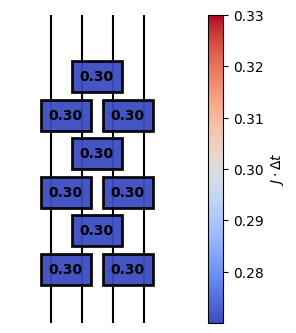

In [6]:
# The package's own circuit drawer: colour = J*dt of each coupler
visualize_circuit(circuit.get_coupling_matrix(), figsize=(3, 4))

### 3.2 Run it

`circuit.run(rho, options)` evolves the state **in place**: it overwrites the tensors inside `rho`. So we always run on a **clone** of the input. (Forgetting this is the most common bug when you start running the same input through several circuits.)

For each two-site gate the code contracts the two site tensors, applies the gate, and splits them back with a truncated SVD (`src/svd_trunc.py`). The new singular values go into `rho.SL`.

In [7]:
rho = rho_in.clone()
t0 = time.time()
circuit.run(rho, options=OPTIONS)
print(f"forward pass took {1e3 * (time.time() - t0):.1f} ms")

print("bond dimensions after circuit:", rho.get_BDs(), " (max possible here: 1, 5, 25, 5, 1)")
print("right-canonical?             :", rho.is_canonical())
print("<n_l>                        :", rho.number_expectations())
print("total photon number          :", rho.number_expectations().sum().item(), "(the circuit conserves it)")

forward pass took 13.0 ms
bond dimensions after circuit: [1, 5, 9, 5, 1]  (max possible here: 1, 5, 25, 5, 1)
right-canonical?             : True
<n_l>                        : tensor([0.6410, 0.2450, 0.1041, 0.0069], dtype=torch.float64)
total photon number          : 0.997055574580661 (the circuit conserves it)


### 3.3 Check against the dense simulation

In [8]:
R_out = dense_run(circuit, R_in)
R_mps = mpdo_to_dense(rho)

print("max |rho_MPS - rho_dense| =", (R_mps - R_out).abs().max().item())
print("dense <n_l>:", [round(dense_expect(R_out, (ops.n, l)).real.item(), 6) for l in range(N_CHANNELS)])
print("MPS   <n_l>:", [round(v, 6) for v in rho.number_expectations().tolist()])

max |rho_MPS - rho_dense| = 6.182914327352636e-09
dense <n_l>: [0.641048, 0.245024, 0.104059, 0.006924]
MPS   <n_l>: [0.641048, 0.245024, 0.104059, 0.006924]


Close agreement in the density matrix and even better in the simple observables. The residual comes from the SVD steps; tighten `cutoff_BD` and it shrinks.

### 3.4 Entanglement along the chain

`entropy_profile()` returns the von Neumann entropy $S = -\sum_k s_k^2\log s_k^2$ of the singular values on every bond. A product state has $S = 0$ everywhere; the beam splitters build entanglement as the photon spreads.

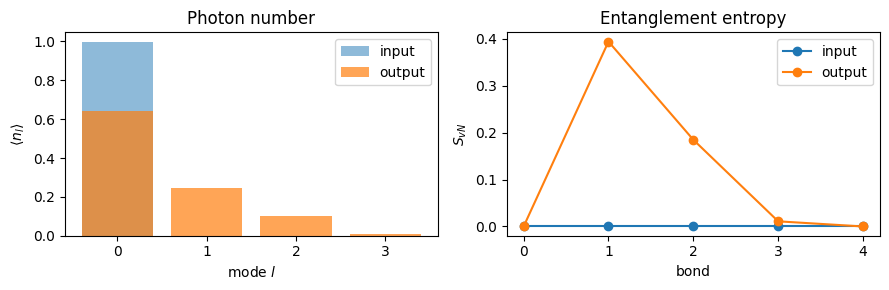

In [9]:
S_in, S_out = rho_in.entropy_profile(), rho.entropy_profile()
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(range(N_CHANNELS), rho_in.number_expectations(), alpha=0.5, label="input")
ax[0].bar(range(N_CHANNELS), rho.number_expectations(), alpha=0.7, label="output")
ax[0].set(xlabel="mode $l$", ylabel=r"$\langle n_l\rangle$", title="Photon number"); ax[0].legend()
ax[1].plot(range(N_CHANNELS + 1), S_in, "o-", label="input")
ax[1].plot(range(N_CHANNELS + 1), S_out, "o-", label="output")
ax[1].set(xlabel="bond", ylabel="$S_{vN}$", title="Entanglement entropy"); ax[1].legend()
plt.tight_layout(); plt.show()

**Try it:** set `U_KERR = 0` and rerun this section. A coherent state through a linear network stays an exact *product* of coherent states, so ideally the entanglement would vanish. You will instead see a small but nonzero entropy ($S\sim 10^{-2}$ at `NMAX = 4`). That residue is an artefact of the Fock cutoff: the truncated beam splitter is not exactly linear optics. Raise `NMAX` to 8 and it drops to $\sim10^{-5}$. With $U \neq 0$, by contrast, the entanglement is physical and does not go away.

## 4. Observables

### 4.1 Built-in local quantities

`MPDOtorch` has methods for the usual single-mode quantities:

| method | quantity |
|---|---|
| `number_expectations()` | $\langle n_l\rangle$ |
| `number_variances()` | $\langle n_l^2\rangle - \langle n_l\rangle^2$ |
| `density_correlations(n_eps)` | $g^{(2)}_l(0) = \dfrac{\langle n_l(n_l-1)\rangle + \epsilon^2}{\langle n_l\rangle^2 + \epsilon^2}$ |
| `ptrace(l)` | single-site reduced density matrix $\rho_l$ (multi-site: see 4.5) |

A coherent state has $g^{(2)}(0)=1$. Values $<1$ (antibunching, a single-photon-like signature) or $>1$ (bunching) are created by the Kerr nonlinearity.

The $\epsilon$ regulariser keeps $g^{(2)}$ finite in nearly empty modes. Read $g^{(2)}$ only where $\langle n\rangle \gg \epsilon$.

In [10]:
n_eps = 1e-3
print("<n_l>     :", rho.number_expectations())
print("Var(n_l)  :", rho.number_variances())
print("g2_l(0)   :", rho.density_correlations(n_eps))

# Same from the dense matrix (no regulariser needed where <n> is not tiny)
for l in range(N_CHANNELS):
    nl  = dense_expect(R_out, (ops.n, l)).real
    c2  = dense_expect(R_out, (ops.n_nm1, l)).real
    print(f"  dense g2_{l} = {((c2 + n_eps**2) / (nl**2 + n_eps**2)).item():.6f}")

rho_0 = rho.ptrace(0)
print("\nreduced density matrix of mode 0: trace =", torch.trace(rho_0).real.item())
print("Fock populations p(n) in mode 0 :", torch.diagonal(rho_0).real)

<n_l>     : tensor([0.6410, 0.2450, 0.1041, 0.0069], dtype=torch.float64)
Var(n_l)  : tensor([0.9636, 0.2461, 0.1021, 0.0069], dtype=torch.float64)
g2_l(0)   : tensor([1.7850, 1.0181, 0.8169, 0.9186], dtype=torch.float64)
  dense g2_0 = 1.785006


  dense g2_1 = 1.018112
  dense g2_2 = 0.816866
  dense g2_3 = 0.918558

reduced density matrix of mode 0: trace = 1.0000000000000007
Fock populations p(n) in mode 0 : tensor([0.6245, 0.1939, 0.1153, 0.0490, 0.0174], dtype=torch.float64)


### 4.2 Two-point correlators: the transfer-matrix picture

For two sites $i<j$ we want

$$C_{ij} = \mathrm{Tr}\big[\rho\,O_i\,O_j\big].$$

Because the tensors are right-canonical, everything to the right of site $j$ contracts to the identity, and the singular values $s^{(i)}$ on the bond left of site $i$ summarise everything to the left. The contraction is then a left-to-right sweep of a small **bond environment** $G_{\alpha\alpha'}$ (one ket and one bra bond index):

1. **Open** at site $i$: contract $B^{[i]}$, its conjugate and $O_i$, weighted by $s^{(i)}$. This leaves the right bond open.
2. **Propagate** through every site $i<m<j$ with the operator-free **transfer matrix**
$$G'_{\beta\beta'} = \sum_{b,\alpha,\alpha',p} G_{\alpha\alpha'}\, B^{[m]}_{b\alpha p\beta}\, B^{[m]*}_{b\alpha' p\beta'} ,$$
where the physical index $p$ and the purification index $b$ are traced at each site. The trace over $b$ is what makes this work for mixed states too.
3. **Close** at site $j$ with $O_j$, and trace the right bond.

Each step costs $O(\chi^3 d)$, so a correlator is $O(N\chi^3 d)$ instead of the $d^{2N}$ of the dense matrix. That scaling gap is the whole reason to use tensor networks.

On `MPDO-dev` this is implemented as:

| method | returns |
|---|---|
| `rho.correlation(op1, (i, j), op2=None)` | one pair $\langle O^{(1)}_i O^{(2)}_j\rangle$ (sites are sorted internally) |
| `rho.correlation_matrix(op1, op2=None, is_hermitian=True)` | full $N\times N$ matrix in **one sweep per row**, so $O(N^2)$ instead of $O(N^3)$ |
| `rho.cumulant(ops, sites, store=True)` | any number of operators on distinct sites, with cached transfer matrices (section 4.4) |

Start with the density–density correlator and check it against the dense reference:

In [11]:
for (i, j) in [(0, 1), (0, 2), (1, 3)]:
    mps   = rho.correlation(ops.n, (i, j)).real
    dense = dense_expect(R_out, (ops.n, i), (ops.n, j)).real
    print(f"<n_{i} n_{j}>   MPS = {mps.item():.10f}   dense = {dense.item():.10f}")

<n_0 n_1>   MPS = 0.0479777653   dense = 0.0479777653
<n_0 n_2>   MPS = 0.0185712542   dense = 0.0185712542


<n_1 n_3>   MPS = 0.0014261474   dense = 0.0014261474


#### A convention to be aware of: operators enter transposed

All the contractions above, and `local_expectation`, evaluate $\sum_{q,r} O_{qr}\,\psi_q\psi_r^* = \langle O^{T}\rangle$. For real symmetric operators ($n$, $n(n-1)$, $a+a^\dagger$) that is the same thing, so the cell above is fine. For $a$ and $a^\dagger$ it is not: $a^T = a^\dagger$, so `correlation(ops.ad, (i, j), ops.a)` actually returns $\langle a_i a_j^\dagger\rangle = \langle a_i^\dagger a_j\rangle^*$.

In [12]:
# compute operator correlation <ad_i a_j > with (i,j) = (0,1)
lib = rho.correlation(op1=ops.ad, op2=ops.a, sites=(0, 1))
print("correlation(ad, (0,1), a) :", lib)

# compare with exact simulation
print("dense <a0^dag a1>         :", dense_expect(R_out, (ops.ad, 0), (ops.a, 1)))
print("dense <a0 a1^dag>         :", dense_expect(R_out, (ops.a, 0), (ops.ad, 1)))

correlation(ad, (0,1), a) : tensor(-0.0673+0.1208j, dtype=torch.complex128)
dense <a0^dag a1>         : tensor(-0.0673+0.1208j, dtype=torch.complex128)
dense <a0 a1^dag>         : tensor(-0.0673-0.1208j, dtype=torch.complex128)


The library result matches the second line, not the first. For a one-body density matrix the practical consequence is simple. `correlation_matrix(ad, a)` returns $G^T$, the transpose of $G_{ij} = \langle a_i^\dagger a_j\rangle$, and since $G$ is Hermitian that is just $G^*$. So we take `.T` below and let the dense check confirm it. (If the einsums are changed to contract `op.T`, drop the `.T` here. The dense check will tell you immediately which convention is in force.)

### 4.3 Correlation matrices

Two physically useful matrices:

* the **one-body density matrix** $G_{ij} = \langle a_i^\dagger a_j\rangle$: the diagonal holds the photon numbers, and the off-diagonal entries measure first-order coherence between modes;
* the **connected density–density correlator** $C_{ij} = \langle n_i n_j\rangle - \langle n_i\rangle\langle n_j\rangle$.

For coherent light through a *linear* network the output is still a product of coherent states, so $C_{ij}=0$ for $i\neq j$. Nonzero off-diagonal $C_{ij}$ is a fingerprint of the Kerr nonlinearity.

max |G - G_dense| = 0.2504696794192605
max |C - C_dense| = 3.9969416665286417e-13
G is Hermitian    : True


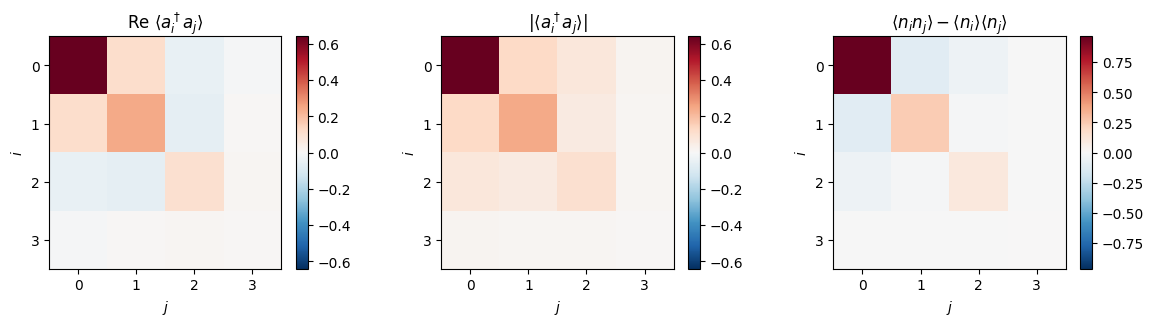

In [13]:
G = rho.correlation_matrix(ops.ad, ops.a).T            # .T: see the transpose convention above
n_vec = rho.number_expectations()
C = rho.correlation_matrix(ops.n).real - torch.outer(n_vec, n_vec)

# Cross-check every entry against the dense simulation
G_dense = torch.tensor([[dense_expect(R_out, (ops.ad, i), (ops.a, j)) for j in range(N_CHANNELS)]
                        for i in range(N_CHANNELS)])
C_dense = torch.tensor([[dense_expect(R_out, (ops.n, i), (ops.n, j)).real for j in range(N_CHANNELS)]
                        for i in range(N_CHANNELS)]) - torch.outer(n_vec, n_vec)
print("max |G - G_dense| =", (G - G_dense).abs().max().item())
print("max |C - C_dense| =", (C - C_dense).abs().max().item())
print("G is Hermitian    :", torch.allclose(G, G.conj().T, atol=1e-10))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a_, M, title in [(ax[0], G.real, r"Re $\langle a_i^\dagger a_j\rangle$"),
                     (ax[1], G.abs(), r"$|\langle a_i^\dagger a_j\rangle|$"),
                     (ax[2], C, r"$\langle n_i n_j\rangle - \langle n_i\rangle\langle n_j\rangle$")]:
    vmax = M.abs().max().item()
    im = a_.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    a_.set(title=title, xlabel="$j$", ylabel="$i$", xticks=range(N_CHANNELS), yticks=range(N_CHANNELS))
    plt.colorbar(im, ax=a_, fraction=0.046)
plt.tight_layout(); plt.show()

A normalised version of $C$ that experimentalists measure directly is the **cross-correlation**

$$g^{(2)}_{ij}(0) = \frac{\langle n_i n_j\rangle}{\langle n_i\rangle\langle n_j\rangle} = 1 + \frac{C_{ij}}{\langle n_i\rangle\langle n_j\rangle}, \qquad i\neq j.$$

It equals 1 for uncorrelated (e.g. coherent) light; values below 1 mean that detecting a photon in mode $i$ makes a photon in mode $j$ *less* likely. We optimise exactly this quantity in section 6.7.

In [14]:
g2_cross = 1 + C / torch.outer(n_vec, n_vec)
print("cross g2_ij (off-diagonal; entries with mode 3 involve very little light, <n_3> ~ 0.007):")
print(g2_cross.fill_diagonal_(float("nan")))

cross g2_ij (off-diagonal; entries with mode 3 involve very little light, <n_3> ~ 0.007):
tensor([[   nan, 0.3055, 0.2784, 0.5373],
        [0.3055,    nan, 0.5416, 0.8406],
        [0.2784, 0.5416,    nan, 0.9063],
        [0.5373, 0.8406, 0.9063,    nan]], dtype=torch.float64)


### 4.4 Multi-point correlators and cached transfer matrices

`cumulant(ops, sites)` generalises the sweep to any number of operators on distinct sites:

$$\mathrm{Tr}\big[\rho\; O^{(0)}_{s_0} O^{(1)}_{s_1}\cdots O^{(k)}_{s_k}\big].$$

(Despite the name, it returns this raw moment, not a *connected* cumulant. You can build the connected version from moments yourself; see the exercises.)

The interesting part is `store=True`. The operator-free stretches between operator sites are pure transfer matrices that do not depend on which operators you insert. So they are computed once, kept in a lookup table `rho._T` keyed by start site, and reused by every later query. When you scan many correlators on a long chain (e.g. all $\langle n_i n_j n_k\rangle$), most of the work is then lookups rather than contractions.

In [15]:
rho_c = rho.clone()          # clone() starts with an empty cache

val   = rho_c.cumulant([ops.n, ops.n, ops.n], [0, 1, 3], store=True)
dense = dense_expect(R_out, (ops.n, 0), (ops.n, 1), (ops.n, 3))
print(f"<n0 n1 n3>   MPS = {val.real.item():.10e}   dense = {dense.real.item():.10e}")

# Order of (op, site) pairs does not matter; they are sorted internally
print("unsorted input gives the same:", rho_c.cumulant([ops.n, ops.n, ops.n], [3, 0, 1]).real.item())

# Two-point via cumulant agrees with correlation()
print("cumulant([n, n], [0, 3]) =", rho_c.cumulant([ops.n, ops.n], [0, 3]).real.item(),
      "  correlation =", rho_c.correlation(ops.n, (0, 3)).real.item())

print("\ncached transfer matrices, {start site: [end sites]}:",
      {i: list(v.keys()) for i, v in rho_c._T.items()})

<n0 n1 n3>   MPS = 2.0144756048e-04   dense = 2.0144756048e-04
unsorted input gives the same: 0.00020144756047516888
cumulant([n, n], [0, 3]) = 0.0023849249903496335   correlation = 0.002384924990349629

cached transfer matrices, {start site: [end sites]}: {0: [1, 2], 1: [2]}


### 4.5 Simulating a photon-counting measurement

`sample_outcome()` draws one photon-number configuration $(n_0, \dots, n_{N-1})$ from the exact distribution $\langle n_0\cdots n_{N-1}|\rho|n_0\cdots n_{N-1}\rangle$. It does this site by site: it samples $n_0$ from its marginal, conditions the bond environment on that outcome, samples $n_1$, and so on. Every sample is exact and independent (no Markov chain, no burn-in), at a cost of one sweep per sample.

This is how you compare to an experiment that only has a finite number of detection events. Below we estimate $\langle n_l\rangle$ and $C_{02}$ from samples and compare with the exact values. Expect agreement within the statistical error bars, not to machine precision.

2000 samples in 3.7 s   (example: [[0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]])
<n_0>  sampled = 0.6110 +- 0.0213   exact = 0.6410
<n_1>  sampled = 0.2550 +- 0.0114   exact = 0.2450
<n_2>  sampled = 0.1055 +- 0.0071   exact = 0.1041
<n_3>  sampled = 0.0035 +- 0.0013   exact = 0.0069

C_02   sampled = -0.0485 +- 0.0030   exact = -0.0481


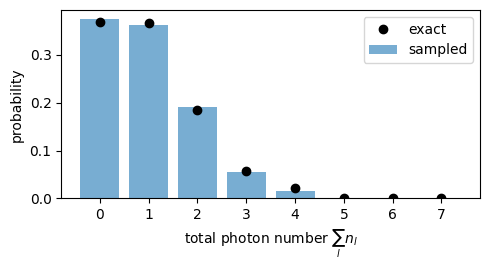

In [16]:
# set random seed
torch.manual_seed(1)

# number of samples to draw from MPS (number Fock basis states)
n_samples = 2000

t0 = time.time() # track time
samples = torch.stack([rho.sample_outcome() for _ in range(n_samples)])   # (n_samples, N_CHANNELS)
print(f"{n_samples} samples in {time.time() - t0:.1f} s   (example: {samples[:3].tolist()})")

mean, err = samples.mean(0), samples.std(0) / n_samples ** 0.5
for l in range(N_CHANNELS):
    print(f"<n_{l}>  sampled = {mean[l]:.4f} +- {err[l]:.4f}   exact = {n_vec[l]:.4f}")

prod = samples[:, 0] * samples[:, 2]
C02_est = prod.mean() - mean[0] * mean[2]
print(f"\nC_02   sampled = {C02_est:.4f} +- {prod.std() / n_samples ** 0.5:.4f}   exact = {C[0, 2]:.4f}")

# Histogram of the total photon number vs. the exact distribution (sum of diagonal of rho by total n)
n_tot = samples.sum(1).long()
nn_all = torch.cartesian_prod(*[torch.arange(D)] * N_CHANNELS).sum(1)
P_exact = torch.zeros(N_CHANNELS * NMAX + 1).index_add_(0, nn_all, torch.diagonal(R_out).real.float())
plt.figure(figsize=(5, 2.8))
plt.bar(range(8), torch.bincount(n_tot, minlength=8)[:8] / n_samples, alpha=0.6, label="sampled")
plt.plot(range(8), P_exact[:8], "ko", label="exact")
plt.xlabel(r"total photon number $\sum_l n_l$"); plt.ylabel("probability"); plt.legend(); plt.tight_layout(); plt.show()

Most estimates land within about $1\text{–}2\sigma$ of the exact values. Mode 3 is the instructive exception: with $\langle n_3\rangle \approx 0.007$ we expect only ~14 detection events in 2000 shots. In that rare-event regime the Gaussian error bar $\sigma/\sqrt{N}$ (computed from the very same few counts) is unreliable, and a "2.5σ" deviation is not alarming. Rerun with a different seed or more samples to convince yourself. Over 20 000 samples, a $\chi^2$ test of the full joint distribution against the exact $\langle \mathbf n|\rho|\mathbf n\rangle$ is perfectly consistent.

## 5. (Optional) Adding loss: where the "DO" in MPDO comes from

So far the state stayed pure (`batch = 1`). Photon loss is modelled with amplitude-damping **Kraus operators** $K_0, K_1, \dots$ applied after every layer. `kraus_dissipation` stacks them into the purification index and truncates it again with an SVD, so you will see the purity dimensions grow. The purity entropy (`entropy_profile(entropy="purity")`) measures how mixed each site has become.

All the observables from section 4 (correlators, `cumulant`, `ptrace`, `sample_outcome`) work unchanged on the mixed state, because they all trace over the purification index.

Note: the Kraus step and `canonical_form` use the randomised `torch.svd_lowrank` for speed, so lossy runs are not bit-for-bit reproducible across seeds. Keep that in mind when you optimise lossy circuits.

In [17]:
lossy = create_nonlinear_photonic_circuit(
    num_layers=N_LAYERS, num_channels=N_CHANNELS, J=J_INIT, U=U_KERR, Nmax=NMAX, dt=DT,
    gamma=0.05, order_kraus=2, device=DEVICE, requires_grad=False,
)
rho_lossy = rho_in.clone()
lossy.run(rho_lossy, options=OPTIONS)

n_lossy = rho_lossy.number_expectations()
C_lossy = rho_lossy.correlation_matrix(ops.n).real - torch.outer(n_lossy, n_lossy)

print("purity dims  lossless:", rho.get_PDs(), "  lossy:", rho_lossy.get_PDs())
print("total <n>    lossless: %.4f   lossy: %.4f" % (n_vec.sum(), n_lossy.sum()))
print("purity entropy per site (lossy):", rho_lossy.entropy_profile(entropy="purity"))
print("C_01  lossless: %.4f   lossy: %.4f" % (C[0, 1], C_lossy[0, 1]))

purity dims  lossless: [1, 1, 1, 1]   lossy: [31, 38, 22, 10]
total <n>    lossless: 0.9971   lossy: 0.7329
purity entropy per site (lossy): tensor([0.4400, 0.1228, 0.0213, 0.0012], dtype=torch.float64)
C_01  lossless: -0.1091   lossy: -0.0600


## 6. Backward pass: differentiating through the simulation

Every operation above (matrix exponentials for the gates, einsums, truncated SVDs) is a PyTorch op, so autograd can differentiate any observable with respect to the circuit parameters. That includes the correlators from section 4. The truncated SVD has a custom, numerically stable backward pass in `src/svd_trunc.py`; that is the non-trivial part of the package.

### 6.1 Trainable circuit

Rebuild the circuit with `requires_grad=True`. Each coupler's $J$ becomes a leaf tensor, and `get_variables()` collects them for an optimiser.

**One gotcha.** Each gate computes its `gate_tensor = exp(-i dt H(J))` *once*, when it is constructed or when `update()` is called. After `optimizer.step()` changes $J$ in place, the cached gate tensors are stale (and their autograd graph has been freed by the previous `backward()`). So every forward pass must start by calling `circuit.update(...)`, which rebuilds all gate tensors from the current $J$ values inside the new graph.

In [18]:
def make_trainable_circuit():
    return create_nonlinear_photonic_circuit(
        num_layers=N_LAYERS, num_channels=N_CHANNELS,
        J=J_INIT, U=U_KERR, Nmax=NMAX, dt=DT,
        device=DEVICE, requires_grad=True,
    )

train_circuit = make_trainable_circuit()
params = train_circuit.get_variables()
print(f"{len(params)} trainable couplings, dtype {params[0].dtype}")


def forward(circ) -> MPDOtorch:
    circ.update(circ.get_J_matrix(float_vals=False))   # rebuild gate tensors from current J
    r = rho_in.clone()                                  # never mutate the input (also: fresh correlator cache)
    circ.run(r, options=OPTIONS)
    return r

9 trainable couplings, dtype torch.float32


### 6.2 Objective: route the light to the last mode

As a first task, we ask the circuit to send as much light as possible into mode 3, the one farthest from the input. Loss = minus the fraction of photons in the target mode:

$$\mathcal L(J) = -\frac{\langle n_3\rangle}{\sum_l \langle n_l\rangle}.$$

With $U=0$ this would be a linear-optics routing problem. With the Kerr term the photon-number components pick up different phases, so a perfect solution is generally not reachable.

Some gradients below come out **exactly zero**, and that is physics, not a bug. Parameters are ordered layer by layer, left to right (`p0` = layer 0 on modes (0,1), `p1` = layer 0 on (2,3), `p2` = layer 1 on (1,2), and so on). `p1` acts on modes that are still in vacuum. `p6` (layer 4, modes 0–1) and `p8` (last layer, modes 1–2) lie outside the backward light cone of $n_3$: no later gate carries their effect to mode 3 before the measurement.

In [19]:
TARGET = N_CHANNELS - 1

def loss_fn(r: MPDOtorch) -> torch.Tensor:
    n = r.number_expectations()
    return -n[TARGET] / n.sum()

r = forward(train_circuit)
loss = loss_fn(r)
loss.backward()
print("initial loss:", loss.item())
print("dL/dJ       :", torch.cat([p.grad for p in params]))

initial loss: -0.006944633414287753
dL/dJ       : tensor([-0.0351,  0.0000, -0.0231, -0.0071, -0.0112, -0.0194, -0.0000, -0.0314,
        -0.0000])


### 6.3 Always check your gradients

Before trusting an optimiser, compare autograd against a central finite difference $\big[\mathcal L(J+\varepsilon) - \mathcal L(J-\varepsilon)\big]/2\varepsilon$ for a few parameters. If these disagree, nothing downstream can be trusted.

(The factory creates $J$ as `float32`, which limits the finite-difference precision to about 4 digits. Build $J$ in `float64` if you need tighter checks.)

In [20]:
def fd_check(circ, params, loss_fn, ks, eps=1e-3):
    # Compare autograd with central finite differences for the parameters listed in ks
    for p in params:
        p.grad = None
    loss_fn(forward(circ)).backward()
    autograd = torch.cat([p.grad for p in params]).clone()
    print(f"{'param':>5} {'autograd':>12} {'finite diff':>12} {'rel. err':>10}")
    for k in ks:
        with torch.no_grad():
            params[k] += eps;      L_plus  = loss_fn(forward(circ))
            params[k] -= 2 * eps;  L_minus = loss_fn(forward(circ))
            params[k] += eps
        fd = ((L_plus - L_minus) / (2 * eps)).item()
        print(f"{k:>5} {autograd[k].item():>12.6f} {fd:>12.6f} {abs(fd - autograd[k].item()) / abs(fd):>10.1e}")
    for p in params:
        p.grad = None

fd_check(train_circuit, params, loss_fn, ks=[0, 2, 5, 7])   # parameters with nonzero gradient (see above)

param     autograd  finite diff   rel. err
    0    -0.035078    -0.035078    9.7e-07
    2    -0.023101    -0.023101    1.2e-06
    5    -0.019412    -0.019412    1.3e-06
    7    -0.031356    -0.031356    1.1e-06


### 6.4 Optimise with Adam

A standard PyTorch loop: zero the gradients, run the forward pass, compute the loss, backpropagate, step. Each iteration is a full forward and backward simulation, a few tens of milliseconds here.

In [21]:
def train(circ, params, loss_fn, steps=120, lr=0.05, report=20, monitor=None):
    optimizer = torch.optim.Adam(params, lr=lr)
    history = []
    t0 = time.time()
    for step in range(steps):
        optimizer.zero_grad()
        r = forward(circ)
        loss = loss_fn(r)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        if step % report == 0:
            extra = f"   {monitor(r)}" if monitor else ""
            print(f"step {step:3d}   loss {loss.item():+.4f}{extra}")
    print(f"{steps} steps in {time.time() - t0:.1f} s")
    return history

J_before = train_circuit.get_coupling_matrix()
n_before = forward(train_circuit).number_expectations().detach()

history = train(train_circuit, params, loss_fn,
                monitor=lambda r: f"<n> = {r.number_expectations().detach().numpy().round(3)}")

r_opt = forward(train_circuit)
n_after = r_opt.number_expectations().detach()

step   0   loss -0.0069   <n> = [0.641 0.245 0.104 0.007]
step  20   loss -0.6023   <n> = [0.062 0.099 0.236 0.601]
step  40   loss -0.7262   <n> = [0.088 0.091 0.094 0.724]
step  60   loss -0.7769   <n> = [0.036 0.154 0.033 0.775]
step  80   loss -0.9352   <n> = [0.018 0.029 0.018 0.932]
step 100   loss -0.9540   <n> = [0.015 0.017 0.014 0.951]
120 steps in 6.5 s


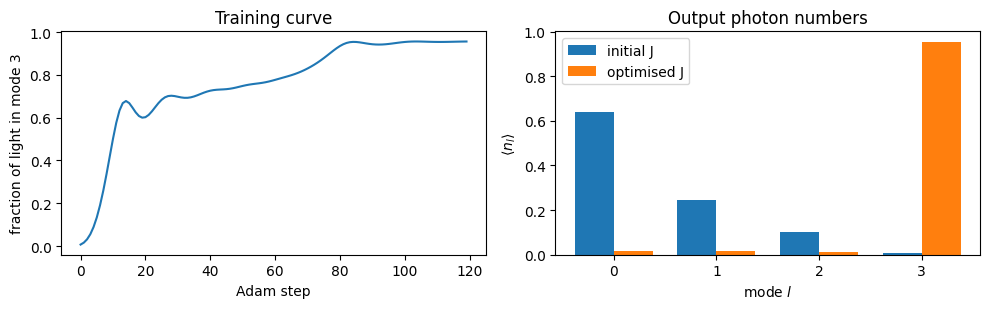

couplings J*dt before:


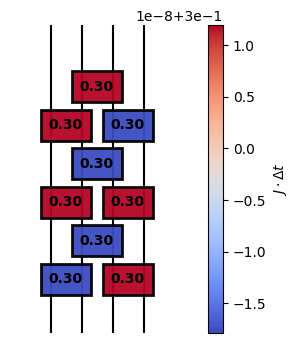

couplings J*dt after:


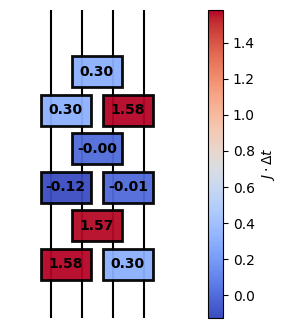

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot([-h for h in history])
ax[0].set(xlabel="Adam step", ylabel=f"fraction of light in mode {TARGET}", title="Training curve")
w = 0.38
ax[1].bar(np.arange(N_CHANNELS) - w / 2, n_before, w, label="initial J")
ax[1].bar(np.arange(N_CHANNELS) + w / 2, n_after, w, label="optimised J")
ax[1].set(xlabel="mode $l$", ylabel=r"$\langle n_l\rangle$", title="Output photon numbers", xticks=range(N_CHANNELS))
ax[1].legend(); plt.tight_layout(); plt.show()

print("couplings J*dt before:"); visualize_circuit(J_before, figsize=(3, 4))
print("couplings J*dt after:");  visualize_circuit(train_circuit.get_coupling_matrix(), figsize=(3, 4))

### 6.5 Verify the optimised circuit independently

An optimiser can exploit bugs (a truncation that is too aggressive, a cutoff that is too low) and report a great loss for an unphysical state. So we rerun the final circuit through the dense simulator and check it agrees.

In [23]:
R_opt = dense_run(train_circuit, R_in)
n_dense = torch.tensor([dense_expect(R_opt, (ops.n, l)).real for l in range(N_CHANNELS)])
print("MPS   <n_l>:", n_after.numpy().round(6))
print("dense <n_l>:", n_dense.numpy().round(6))
print("max deviation:", (n_after - n_dense).abs().max().item())
print("\ng2 in the target mode:", r_opt.density_correlations(n_eps)[TARGET].item())

MPS   <n_l>: [0.014728 0.014929 0.013997 0.953402]
dense <n_l>: [0.014728 0.014929 0.013997 0.953402]
max deviation: 2.8216013969739606e-09

g2 in the target mode: 0.9429558378196099


### 6.6 The same thing with the package's training loop

For real experiments the repo provides `epoch_optimize` (and a layer-by-layer `sweeping_optimize`) in `src/mpdo_optimizer.py`. It expects an objective with signature `objective(epoch, rho, obj_params, do_tracking)` that receives a **fresh clone** of the input state and returns a scalar loss. The loop handles cloning, NaN checks, LBFGS closures, parameter clamping and schedulers. It prints a couple of lines per epoch.

In [24]:
from src.mpdo_optimizer import epoch_optimize

def objective(epoch, rho_local, obj_params, do_tracking=False):
    train_circuit.update(train_circuit.get_J_matrix(float_vals=False))
    train_circuit.run(rho_local, options=OPTIONS)
    return loss_fn(rho_local)

opt2 = torch.optim.Adam(params, lr=0.02)
epoch_optimize(objective, opt2, rho_in, max_epochs=5, epoch_print=1)


Running opt epoch 1...
Epoch 1 finished in 0.09s, objective: -9.562172e-01
Total runtime: 0.09s

Running opt epoch 2...
Epoch 2 finished in 0.06s, objective: -9.548088e-01
Total runtime: 0.15s

Running opt epoch 3...


Epoch 3 finished in 0.06s, objective: -9.560902e-01
Total runtime: 0.21s

Running opt epoch 4...
Epoch 4 finished in 0.06s, objective: -9.559905e-01
Total runtime: 0.26s

Running opt epoch 5...
Epoch 5 finished in 0.06s, objective: -9.554579e-01
Total runtime: 0.32s


### 6.7 Optimising a correlator: anticorrelated outputs

Correlators are differentiable like any other observable, so they can be objectives too. A nonlinear target: make the two **edge modes anticorrelated** by minimising their connected density correlator

$$\mathcal L(J) = C_{03} = \langle n_0 n_3\rangle - \langle n_0\rangle\langle n_3\rangle .$$

For coherent input through a linear network $C_{03} = 0$ regardless of $J$, so any negative value the optimiser finds is created by the Kerr interaction. We minimise the unnormalised $C_{03}$ rather than the cross-$g^{(2)}_{03}$ directly, because the ratio can be made small trivially by emptying one of the modes.

In [25]:
corr_circuit = make_trainable_circuit()
corr_params = corr_circuit.get_variables()

def corr_loss(r: MPDOtorch) -> torch.Tensor:
    n = r.number_expectations()
    return r.correlation(ops.n, (0, 3)).real - n[0] * n[3]

def corr_monitor(r):
    n = r.number_expectations().detach()
    C03 = (r.correlation(ops.n, (0, 3)).real - n[0] * n[3]).item()
    return f"<n> = {n.numpy().round(3)}   cross-g2_03 = {1 + C03 / (n[0] * n[3]).item():.3f}"

fd_check(corr_circuit, corr_params, corr_loss, ks=[0, 2, 4])
corr_history = train(corr_circuit, corr_params, corr_loss, monitor=corr_monitor)

param     autograd  finite diff   rel. err
    0    -0.006414    -0.006414    6.2e-07
    2    -0.004926    -0.004926    1.5e-06
    4    -0.002447    -0.002447    1.5e-06
step   0   loss -0.0021   <n> = [0.641 0.245 0.104 0.007]   cross-g2_03 = 0.537
step  20   loss -0.1035   <n> = [0.476 0.019 0.067 0.435]   cross-g2_03 = 0.500
step  40   loss -0.1297   <n> = [0.461 0.011 0.008 0.517]   cross-g2_03 = 0.456
step  60   loss -0.1318   <n> = [0.468 0.004 0.004 0.52 ]   cross-g2_03 = 0.460
step  80   loss -0.1318   <n> = [0.466 0.004 0.004 0.522]   cross-g2_03 = 0.459
step 100   loss -0.1318   <n> = [0.467 0.004 0.004 0.522]   cross-g2_03 = 0.459
120 steps in 6.9 s


C_03   MPS = -0.13184872   dense = -0.13184872
cross-g2_03 = 0.459  (1 = uncorrelated)


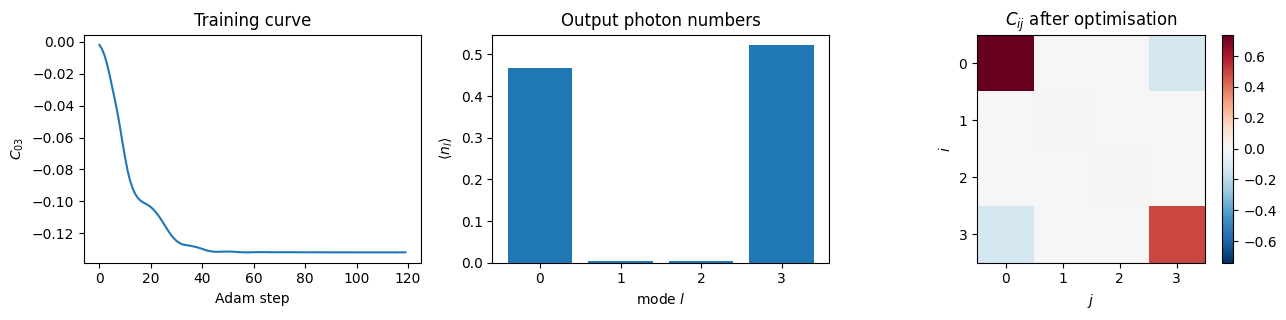

In [26]:
r_c = forward(corr_circuit)
n_c = r_c.number_expectations().detach()
C_c = (r_c.correlation_matrix(ops.n).real - torch.outer(n_c, n_c)).detach()

# Independent dense check of the optimised correlator
R_c = dense_run(corr_circuit, R_in)
C03_dense = (dense_expect(R_c, (ops.n, 0), (ops.n, 3)).real
             - dense_expect(R_c, (ops.n, 0)).real * dense_expect(R_c, (ops.n, 3)).real)
print(f"C_03   MPS = {C_c[0, 3]:.8f}   dense = {C03_dense:.8f}")
print(f"cross-g2_03 = {1 + C_c[0, 3] / (n_c[0] * n_c[3]):.3f}  (1 = uncorrelated)")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(corr_history); ax[0].set(xlabel="Adam step", ylabel="$C_{03}$", title="Training curve")
ax[1].bar(range(N_CHANNELS), n_c); ax[1].set(xlabel="mode $l$", ylabel=r"$\langle n_l\rangle$",
                                             title="Output photon numbers", xticks=range(N_CHANNELS))
vmax = C_c.abs().max().item()
im = ax[2].imshow(C_c, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax[2].set(title=r"$C_{ij}$ after optimisation", xlabel="$j$", ylabel="$i$",
          xticks=range(N_CHANNELS), yticks=range(N_CHANNELS))
plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

The optimiser splits the light roughly evenly between the two edges and empties the middle modes. The cross-correlation $g^{(2)}_{03}\approx 0.46$ means photon pairs tend to exit *together* on one side rather than one on each side. The Kerr circuit already anticorrelates the modes at the initial couplings (look at the cross-$g^{(2)}$ table in 4.3). What the optimiser adds is to bring substantial light into *both* edge modes while keeping that anticorrelation, which is why $|C_{03}|$ grows by a factor of ~60.

**Try it:** rerun with `U_KERR = 0`. The optimiser still splits the light 50/50, but $C_{03}$ only reaches about $-0.005$ instead of $-0.13$. That small residue is the same Fock-cutoff artefact as in section 3.4, and it shrinks as you raise `NMAX`.

## 7. Exercises
For you to get used to the code. At some point it is probably better convert them to individual scripts and make use of GPU.

0. **Source code.** Look up functions in the source code folder `src/` and try to get an understanding of the tensor operations.
1. **Cutoff convergence.** Repeat section 3 with `NMAX = 3, 4, 6` and $|\alpha|^2 = 1, 2$. How large does `NMAX` have to be before $\langle n_l\rangle$ and $g^{(2)}_l$ stop changing to 4 digits?
2. **Truncation.** Set `max_BD = 2` in `OPTIONS`. How large is the error in $G$ and $C$ against the dense result? Plot error vs. `max_BD`.
3. **Linear limit.** With `U_KERR = 0`, show that $C_{ij}\to0$ for $i\neq j$ and that the entanglement entropy goes to zero as you raise `NMAX`. Explain why it is not exactly zero at finite cutoff.
4. **Connected three-point cumulant.** Use `cumulant` to compute $\kappa_3 = \langle n_0 n_1 n_2\rangle - \sum \langle n_i n_j\rangle\langle n_k\rangle + 2\langle n_0\rangle\langle n_1\rangle\langle n_2\rangle$ (the sum runs over the three ways to split the triple) and check it against the dense simulation.
5. **Sampling statistics.** Repeat 4.6 for `n_samples = 250, 1000, 4000` and verify the error on $C_{02}$ shrinks as $1/\sqrt{n_\text{samples}}$. How many samples would an experiment need to resolve the anticorrelation found in 6.7?
6. **Antibunching.** Change the objective to minimise $g^{(2)}(0)$ in a single mode while keeping its $\langle n\rangle$ above a threshold, e.g. $\mathcal L = g^{(2)}_3 + \lambda\,\mathrm{ReLU}(0.2 - \langle n_3\rangle)$. Can you get below 1?
7. **Lossy optimisation.** Repeat 6.7 with `gamma=0.02`. How does loss degrade the achievable anticorrelation? (See the note on `svd_lowrank` in section 5.)
8. **Scaling and caching.** Increase `N_CHANNELS` to 12 and 20 (drop the dense checks). Time a full scan of all $\langle n_i n_j n_k\rangle$ with `cumulant(..., store=True)` vs `store=False`.
